In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Data/kc_house_data.csv")

print(df.shape)
df.head()

(21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


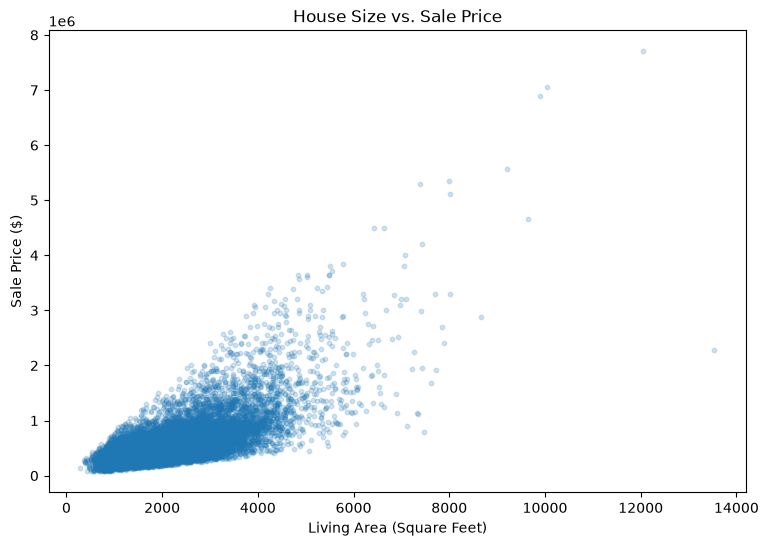

In [2]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["sqft_living"],
    df["price"],
    alpha=0.2,
    s=10
)

plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Sale Price ($)")
plt.title("House Size vs. Sale Price")

plt.show()

In [3]:
from sklearn.linear_model import LinearRegression
import pandas as pd

# Historical data
X = df[["sqft_living"]]
y = df["price"]

# Step 1: Train the model
model = LinearRegression()
model.fit(X, y)

# Step 2: Give the model a new house size
new_house = pd.DataFrame({
    "sqft_living": [2000]
})

# Step 3: Predict its price
predicted_price = model.predict(new_house)

print(f"Predicted price: ${predicted_price[0]:,.2f}")

Predicted price: $517,666.39


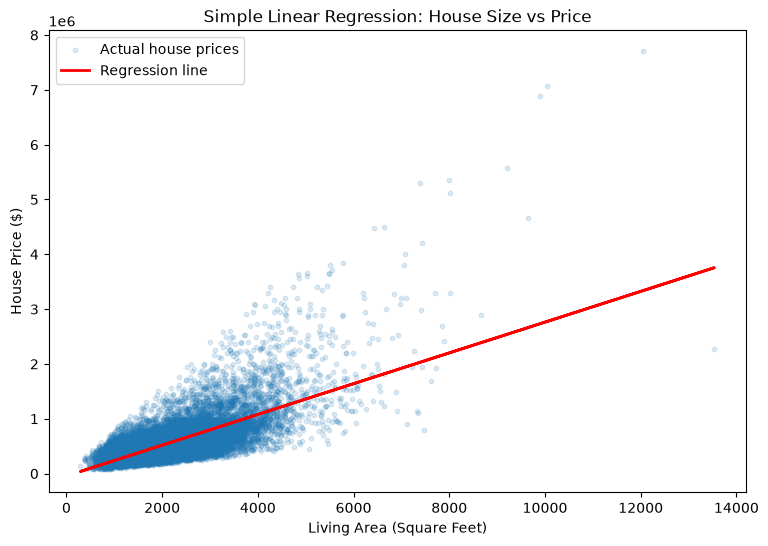

In [4]:
# Predict prices for all houses in our dataset
predicted_prices = model.predict(X)

plt.figure(figsize=(9, 6))

# Actual house sales
plt.scatter(
    X["sqft_living"],
    y,
    alpha=0.15,
    s=10,
    label="Actual house prices"
)

# Linear Regression line
plt.plot(
    X["sqft_living"],
    predicted_prices,
    color="red",
    linewidth=2,
    label="Regression line"
)

plt.xlabel("Living Area (Square Feet)")
plt.ylabel("House Price ($)")
plt.title("Simple Linear Regression: House Size vs Price")
plt.legend()
plt.show()

In [5]:
# Get predictions for all houses
predicted_prices = model.predict(X)

# Calculate residuals
residuals = y - predicted_prices

# Compare actual, predicted, and residual
results = pd.DataFrame({
    "Actual Price": y,
    "Predicted Price": predicted_prices,
    "Residual": residuals
})

results.head(10).round(2)

,Actual Price,Predicted Price,Residual
0,221900.0,287555.07,-65655.07
1,538000.0,677621.83,-139621.83
2,180000.0,172499.40,7500.60
3,604000.0,506441.45,97558.55
4,510000.0,427866.85,82133.15
5,1225000.0,1477398.99,-252398.99
6,257500.0,437688.68,-180188.68
7,291850.0,253880.24,37969.76
8,229500.0,455929.21,-226429.21
9,323000.0,486797.80,-163797.80


In [6]:
from sklearn.model_selection import train_test_split

X = df[["sqft_living"]]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training houses:", len(X_train))
print("Testing houses:", len(X_test))

Training houses: 17290
Testing houses: 4323


In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train using only training data
model = LinearRegression()
model.fit(X_train, y_train)

# Predict prices for unseen houses
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²: {r2:.4f}")

MAE: $177,867.54
RMSE: $276,559.17
R²: 0.4941


In [8]:
# Select three features
features = ["sqft_living", "bedrooms", "bathrooms"]

X = df[features]
y = df["price"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Train Multiple Linear Regression
model_multi = LinearRegression()
model_multi.fit(X_train, y_train)

# Examine learned coefficients
for feature, coefficient in zip(features, model_multi.coef_):
    print(f"{feature}: ${coefficient:,.2f}")

print(f"Intercept: ${model_multi.intercept_:,.2f}")

sqft_living: $305.65
bedrooms: $-56,373.55
bathrooms: $11,296.92
Intercept: $69,884.30


In [9]:
# Predict using our three-feature model
y_pred_multi = model_multi.predict(X_test)

# Evaluate predictions
mae_multi = mean_absolute_error(y_test, y_pred_multi)
rmse_multi = np.sqrt(mean_squared_error(y_test, y_pred_multi))
r2_multi = r2_score(y_test, y_pred_multi)

print(f"MAE: ${mae_multi:,.2f}")
print(f"RMSE: ${rmse_multi:,.2f}")
print(f"R²: {r2_multi:.4f}")

MAE: $174,662.93
RMSE: $272,465.84
R²: 0.5089


In [10]:
# Add waterfront to our existing features
features = [
    "sqft_living",
    "bedrooms",
    "bathrooms",
    "waterfront"
]

X = df[features]
y = df["price"]

# Use the same train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Train the model
model_waterfront = LinearRegression()
model_waterfront.fit(X_train, y_train)

# Evaluate
y_pred = model_waterfront.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R²:", round(r2_score(y_test, y_pred), 4))

print("Waterfront coefficient:", round(model_waterfront.coef_[3], 2))

MAE: 170383.49
RMSE: 259994.65
R²: 0.5529
Waterfront coefficient: 768656.26


In [11]:
for feature, coefficient in zip(features, model_waterfront.coef_):
    print(f"{feature}: ${coefficient:,.2f}")

sqft_living: $294.74
bedrooms: $-49,627.60
bathrooms: $11,451.58
waterfront: $768,656.26


In [12]:
houses = pd.DataFrame({
    "sqft_living": [2000, 3000],
    "bedrooms": [3, 3],
    "bathrooms": [2, 2],
    "waterfront": [1, 0]
})

predictions = model_waterfront.predict(houses)

print(f"House A: ${predictions[0]:,.2f}")
print(f"House B: ${predictions[1]:,.2f}")
print(f"Difference: ${predictions[0] - predictions[1]:,.2f}")

House A: $1,296,098.63
House B: $822,177.52
Difference: $473,921.11


In [13]:
# Check correlation between the two features
correlation = df["sqft_living"].corr(df["sqft_above"])

print(f"Correlation: {correlation:.4f}")

Correlation: 0.8766


In [14]:
# Add a highly correlated feature
features_new = [
    "sqft_living",
    "bedrooms",
    "bathrooms",
    "waterfront",
    "sqft_above"
]

X_new = df[features_new]
y = df["price"]

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y, test_size=0.20, random_state=42
)

# Train a new regression model
model_new = LinearRegression()
model_new.fit(X_train_new, y_train_new)

# Evaluate
predictions_new = model_new.predict(X_test_new)

print("MAE:", round(mean_absolute_error(y_test_new, predictions_new), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_new, predictions_new)), 2))
print("R²:", round(r2_score(y_test_new, predictions_new), 4))

print("\nCOEFFICIENTS")
for feature, coefficient in zip(features_new, model_new.coef_):
    print(f"{feature}: ${coefficient:,.2f}")

MAE: 170241.26
RMSE: 260030.1
R²: 0.5527

COEFFICIENTS
sqft_living: $312.63
bedrooms: $-50,722.38
bathrooms: $13,057.72
waterfront: $763,389.28
sqft_above: $-22.97


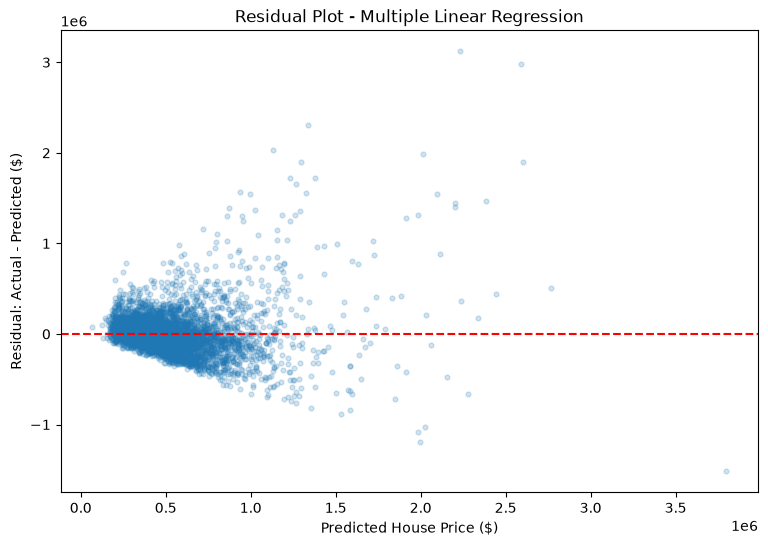

In [15]:
# Use our four-feature regression model
features_4 = [
    "sqft_living",
    "bedrooms",
    "bathrooms",
    "waterfront"
]

# Recreate the same test houses
X_4 = df[features_4]

_, X_test_4, _, y_test_4 = train_test_split(
    X_4,
    df["price"],
    test_size=0.20,
    random_state=42
)

# Predict house prices
predictions = model_waterfront.predict(X_test_4)

# Calculate residuals
residuals = y_test_4 - predictions

# Plot residuals
plt.figure(figsize=(9, 6))

plt.scatter(
    predictions,
    residuals,
    alpha=0.2,
    s=12
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted House Price ($)")
plt.ylabel("Residual: Actual - Predicted ($)")
plt.title("Residual Plot - Multiple Linear Regression")

plt.show()

In [16]:
# Recreate our four-feature dataset
features = [
    "sqft_living",
    "bedrooms",
    "bathrooms",
    "waterfront"
]

X = df[features]
y = df["price"]

# Same train/test split as before
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Our previously trained four-feature model
train_predictions = model_waterfront.predict(X_train)
test_predictions = model_waterfront.predict(X_test)

# Compare errors
train_mae = mean_absolute_error(y_train, train_predictions)
test_mae = mean_absolute_error(y_test, test_predictions)

print(f"Training MAE: ${train_mae:,.2f}")
print(f"Test MAE: ${test_mae:,.2f}")
print(f"Difference: ${test_mae - train_mae:,.2f}")

Training MAE: $165,988.58
Test MAE: $170,383.49
Difference: $4,394.91


In [17]:
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error

# Split existing training data into training and validation
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.25,
    random_state=42
)

# Ordinary Linear Regression
linear = LinearRegression()
linear.fit(X_fit, y_fit)

# Ridge Regression
ridge = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)
ridge.fit(X_fit, y_fit)

# Compare validation performance
linear_pred = linear.predict(X_val)
ridge_pred = ridge.predict(X_val)

print("Linear Regression MAE:",
      round(mean_absolute_error(y_val, linear_pred), 2))

print("Ridge Regression MAE:",
      round(mean_absolute_error(y_val, ridge_pred), 2))

Linear Regression MAE: 167426.35
Ridge Regression MAE: 167423.89


In [18]:
alphas = [0.1, 1, 10, 100, 1000, 10000, 100000]

for alpha in alphas:
    ridge = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    ridge.fit(X_fit, y_fit)
    predictions = ridge.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)

    print(f"Alpha: {alpha:>8} | Validation MAE: ${mae:,.2f}")

Alpha:      0.1 | Validation MAE: $167,426.11
Alpha:        1 | Validation MAE: $167,423.89
Alpha:       10 | Validation MAE: $167,401.77
Alpha:      100 | Validation MAE: $167,200.13
Alpha:     1000 | Validation MAE: $166,564.24
Alpha:    10000 | Validation MAE: $174,721.08
Alpha:   100000 | Validation MAE: $210,122.55


In [19]:
for alpha in [1, 1000, 100000]:
    ridge = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    ridge.fit(X_fit, y_fit)

    print(f"\nALPHA = {alpha}")

    for feature, coefficient in zip(
        X_fit.columns,
        ridge.named_steps["ridge"].coef_
    ):
        print(f"{feature}: {coefficient:,.2f}")


ALPHA = 1
sqft_living: 270,776.11
bedrooms: -44,778.98
bathrooms: 7,313.49
waterfront: 68,809.87

ALPHA = 1000
sqft_living: 227,546.93
bedrooms: -29,616.47
bathrooms: 30,174.22
waterfront: 66,669.29

ALPHA = 100000
sqft_living: 27,143.81
bedrooms: 9,918.21
bathrooms: 19,280.30
waterfront: 10,680.71


In [20]:
from sklearn.linear_model import Lasso

for alpha in [100, 1000, 10000, 50000]:
    lasso = make_pipeline(
        StandardScaler(),
        Lasso(alpha=alpha, max_iter=50000)
    )

    lasso.fit(X_fit, y_fit)

    predictions = lasso.predict(X_val)
    mae = mean_absolute_error(y_val, predictions)

    print(f"\nALPHA = {alpha}")
    print(f"Validation MAE: ${mae:,.2f}")

    for feature, coefficient in zip(
        X_fit.columns,
        lasso.named_steps["lasso"].coef_
    ):
        print(f"{feature}: {coefficient:,.2f}")


ALPHA = 100
Validation MAE: $167,419.49
sqft_living: 270,679.04
bedrooms: -44,564.28
bathrooms: 7,183.47
waterfront: 68,736.96

ALPHA = 1000
Validation MAE: $167,364.08
sqft_living: 269,313.84
bedrooms: -42,459.41
bathrooms: 6,293.98
waterfront: 68,065.69

ALPHA = 10000
Validation MAE: $167,504.48
sqft_living: 253,962.25
bedrooms: -21,652.38
bathrooms: 0.00
waterfront: 61,343.15

ALPHA = 50000
Validation MAE: $168,332.63
sqft_living: 205,129.53
bedrooms: -0.00
bathrooms: 0.00
waterfront: 26,532.31


In [21]:
print("Dataset shape:", df.shape)

feature_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique()
})

display(feature_summary)

Dataset shape: (21613, 21)


,Data Type,Missing Values,Unique Values
id,int64,0,21436
date,str,0,372
price,float64,0,4028
bedrooms,int64,0,13
bathrooms,float64,0,30
sqft_living,int64,0,1038
sqft_lot,int64,0,9782
floors,float64,0,6
waterfront,int64,0,2
view,int64,0,5


In [22]:
from sklearn.model_selection import GroupShuffleSplit

features = [
    "sqft_living",
    "bedrooms",
    "bathrooms",
    "waterfront",
    "grade",
    "condition",
    "view",
    "yr_built"
]

X = df[features]
y = df["price"]

# First split: 80% development, 20% test
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

dev_idx, test_idx = next(
    split1.split(X, y, groups=df["id"])
)

# Second split: 75% training, 25% validation
# of the development portion
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_rel, val_rel = next(
    split2.split(
        X.iloc[dev_idx],
        y.iloc[dev_idx],
        groups=df.iloc[dev_idx]["id"]
    )
)

train_idx = dev_idx[train_rel]
val_idx = dev_idx[val_rel]

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]
y_test = y.iloc[test_idx]

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Training: 12971
Validation: 4318
Test: 4324


In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Original four features
features_4 = [
    "sqft_living",
    "bedrooms",
    "bathrooms",
    "waterfront"
]

# Model 1: Four features
model_4 = LinearRegression()
model_4.fit(X_train[features_4], y_train)

pred_4 = model_4.predict(X_val[features_4])

# Model 2: Eight features
model_8 = LinearRegression()
model_8.fit(X_train, y_train)

pred_8 = model_8.predict(X_val)

# Compare validation performance
print("FOUR-FEATURE MODEL")
print("MAE:", round(mean_absolute_error(y_val, pred_4), 2))
print("R²:", round(r2_score(y_val, pred_4), 4))

print("\nEIGHT-FEATURE MODEL")
print("MAE:", round(mean_absolute_error(y_val, pred_8), 2))
print("R²:", round(r2_score(y_val, pred_8), 4))

FOUR-FEATURE MODEL
MAE: 167256.63
R²: 0.5382

EIGHT-FEATURE MODEL
MAE: 140637.23
R²: 0.6567


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Use the same training and validation houses
numeric_features = [
    "sqft_living", "bedrooms", "bathrooms",
    "waterfront", "grade", "condition",
    "view", "yr_built"
]

all_features = numeric_features + ["zipcode"]

X_train_zip = df.iloc[train_idx][all_features]
X_val_zip = df.iloc[val_idx][all_features]

# One-hot encode ZIP codes
preprocessor = ColumnTransformer(
    transformers=[
        ("zipcode", OneHotEncoder(
            handle_unknown="ignore",
            drop="first"
        ), ["zipcode"]),
        ("numeric", "passthrough", numeric_features)
    ]
)

# Build a complete modeling pipeline
model_zip = Pipeline([
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

# Train
model_zip.fit(X_train_zip, y_train)

# Predict validation houses
pred_zip = model_zip.predict(X_val_zip)

print("EIGHT-FEATURE MODEL")
print("MAE:", round(mean_absolute_error(y_val, pred_8), 2))
print("R²:", round(r2_score(y_val, pred_8), 4))

print("\nEIGHT FEATURES + ZIPCODE")
print("MAE:", round(mean_absolute_error(y_val, pred_zip), 2))
print("R²:", round(r2_score(y_val, pred_zip), 4))

EIGHT-FEATURE MODEL
MAE: 140637.23
R²: 0.6567

EIGHT FEATURES + ZIPCODE
MAE: 97198.34
R²: 0.8271


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

# Prepare preprocessing for Ridge
ridge_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("zipcode", OneHotEncoder(handle_unknown="ignore"), ["zipcode"])
])

# Compare regularization strengths
for alpha in [0.1, 1, 10, 100, 1000]:

    ridge_model = Pipeline([
        ("preprocessor", ridge_preprocessor),
        ("regression", Ridge(alpha=alpha, solver="lsqr"))
    ])

    ridge_model.fit(X_train_zip, y_train)

    predictions = ridge_model.predict(X_val_zip)

    mae = mean_absolute_error(y_val, predictions)
    r2 = r2_score(y_val, predictions)

    print(
        f"Alpha: {alpha:>6} | "
        f"MAE: ${mae:,.2f} | "
        f"R²: {r2:.4f}"
    )

Alpha:    0.1 | MAE: $97,163.48 | R²: 0.8271
Alpha:      1 | MAE: $97,175.84 | R²: 0.8266
Alpha:     10 | MAE: $97,697.28 | R²: 0.8204
Alpha:    100 | MAE: $105,544.07 | R²: 0.7771
Alpha:   1000 | MAE: $128,418.17 | R²: 0.6913


In [26]:
import pandas as pd
import numpy as np

from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Combine training and validation data
X_dev = pd.concat([X_train_zip, X_val_zip])
y_dev = pd.concat([y_train, y_val])

# Prepare reserved test data
X_test_zip = df.iloc[test_idx][all_features]

# Refit our selected Linear Regression pipeline
final_model = clone(model_zip)
final_model.fit(X_dev, y_dev)

# Evaluate on unseen test houses
test_predictions = final_model.predict(X_test_zip)

print("FINAL TEST RESULTS")
print(
    "MAE:",
    round(mean_absolute_error(y_test, test_predictions), 2)
)
print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_test, test_predictions)), 2)
)
print(
    "R²:",
    round(r2_score(y_test, test_predictions), 4)
)

FINAL TEST RESULTS
MAE: 97467.15
RMSE: 165088.18
R²: 0.8049
